In [132]:
import pandas as pd
import numpy as np

full_pumpkins = pd.read_csv('../data/US-pumpkins.csv')

full_pumpkins.head()


,City Name,Type,Package,Variety,Sub Variety,Grade,Date,Low Price,High Price,Mostly Low,...,Unit of Sale,Quality,Condition,Appearance,Storage,Crop,Repack,Trans Mode,Unnamed: 24,Unnamed: 25
0,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,4/29/17,270.0,280.0,270.0,...,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
1,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,5/6/17,270.0,280.0,270.0,...,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
2,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
3,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
4,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,11/5/16,90.0,100.0,90.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN


In [133]:
full_pumpkins.info()

<class 'pandas.DataFrame'>
RangeIndex: 1757 entries, 0 to 1756
Data columns (total 26 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   City Name        1757 non-null   str    
 1   Type             45 non-null     str    
 2   Package          1757 non-null   str    
 3   Variety          1752 non-null   str    
 4   Sub Variety      296 non-null    str    
 5   Grade            0 non-null      float64
 6   Date             1757 non-null   str    
 7   Low Price        1757 non-null   float64
 8   High Price       1757 non-null   float64
 9   Mostly Low       1654 non-null   float64
 10  Mostly High      1654 non-null   float64
 11  Origin           1754 non-null   str    
 12  Origin District  131 non-null    str    
 13  Item Size        1478 non-null   str    
 14  Color            1141 non-null   str    
 15  Environment      0 non-null      float64
 16  Unit of Sale     162 non-null    str    
 17  Quality          0 non-nu

In [134]:
useless_columns = ['Type', 'Sub Variety', 'Grade', 'Origin District', 'Environment', 'Unit of Sale', 'Quality', 'Condition', 'Appearance', 'Storage', 'Crop', 'Repack', 'Trans Mode', 'Unnamed: 24', 'Unnamed: 25']

pumpkins = full_pumpkins.drop(useless_columns, axis=1)
pumpkins = pumpkins[pumpkins['Color'].notna()]
pumpkins['Month'] = pd.to_datetime(pumpkins['Date'], format='%m/%d/%y').dt.month
pumpkins.head(30)


,City Name,Package,Variety,Date,Low Price,High Price,Mostly Low,Mostly High,Origin,Item Size,Color,Month
2,BALTIMORE,24 inch bins,HOWDEN TYPE,9/24/16,160.0,160.0,160.0,160.0,DELAWARE,med,ORANGE,9
3,BALTIMORE,24 inch bins,HOWDEN TYPE,9/24/16,160.0,160.0,160.0,160.0,VIRGINIA,med,ORANGE,9
4,BALTIMORE,24 inch bins,HOWDEN TYPE,11/5/16,90.0,100.0,90.0,100.0,MARYLAND,lge,ORANGE,11
5,BALTIMORE,24 inch bins,HOWDEN TYPE,11/12/16,90.0,100.0,90.0,100.0,MARYLAND,lge,ORANGE,11
6,BALTIMORE,36 inch bins,HOWDEN TYPE,9/24/16,160.0,170.0,160.0,170.0,MARYLAND,med,ORANGE,9
7,BALTIMORE,36 inch bins,HOWDEN TYPE,9/24/16,160.0,160.0,160.0,160.0,PENNSYLVANIA,lge,ORANGE,9
8,BALTIMORE,36 inch bins,HOWDEN TYPE,10/1/16,160.0,170.0,160.0,170.0,MARYLAND,med,ORANGE,10
9,BALTIMORE,36 inch bins,HOWDEN TYPE,10/1/16,160.0,160.0,160.0,160.0,PENNSYLVANIA,lge,ORANGE,10
10,BALTIMORE,36 inch bins,HOWDEN TYPE,10/8/16,160.0,170.0,160.0,170.0,MARYLAND,med,ORANGE,10
11,BALTIMORE,36 inch bins,HOWDEN TYPE,10/8/16,160.0,160.0,160.0,160.0,PENNSYLVANIA,lge,ORANGE,10


Color
ORANGE     916
STRIPED     12
WHITE      213
Name: Color, dtype: int64


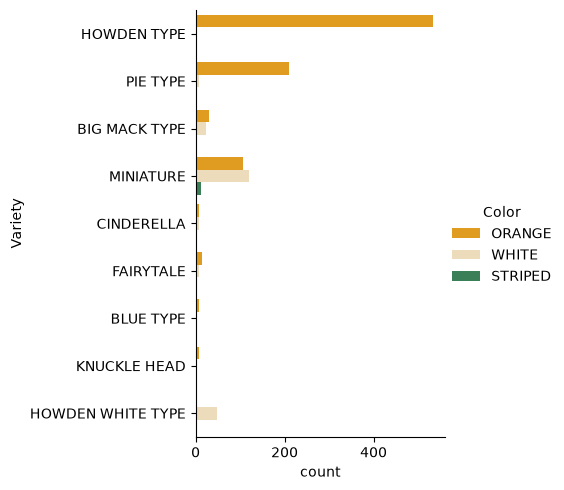

In [135]:
import seaborn as sns

palette = {
    'ORANGE': 'orange',
    'WHITE': 'wheat',
    'STRIPED': 'seagreen',
}

print(pumpkins['Color'].groupby(pumpkins['Color']).count())

sns.catplot(
    data=pumpkins,
    y='Variety',
    hue='Color',
    kind='count',
    palette=palette
)

In [136]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder

pumpkins = pumpkins[pumpkins['Color'] != 'STRIPED'] # Too small amount of striped pumpkins to be useful

item_size_categories = [['sml', 'med', 'med-lge', 'lge', 'xlge', 'jbo', 'exjbo']]
ordinal_encoder = OrdinalEncoder(categories=item_size_categories)

categorical_features = ['City Name', 'Package', 'Variety', 'Origin']
categorical_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

In [137]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

ct = ColumnTransformer(transformers=[
    ('cat', categorical_encoder, categorical_features),
    ('size', Pipeline([
        ('fill', SimpleImputer(strategy='most_frequent')),
        ('ord', ordinal_encoder),
    ]), ['Item Size']),
    ('month', 'passthrough', ['Month'])
    ])

ct.set_output(transform='pandas')
encoded_features = ct.fit_transform(pumpkins)

print(encoded_features.shape)

(1129, 54)


In [138]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
encoded_label = le.fit_transform(pumpkins['Color'])

encoded_pumpkins = encoded_features.assign(Color=encoded_label)

encoded_pumpkins.head()

,cat__City Name_ATLANTA,cat__City Name_BALTIMORE,cat__City Name_BOSTON,cat__City Name_CHICAGO,cat__City Name_COLUMBIA,cat__City Name_DALLAS,cat__City Name_DETROIT,cat__City Name_LOS ANGELES,cat__City Name_MIAMI,cat__City Name_NEW YORK,...,cat__Origin_NORTH CAROLINA,cat__Origin_OHIO,cat__Origin_PENNSYLVANIA,cat__Origin_TENNESSEE,cat__Origin_TEXAS,cat__Origin_VERMONT,cat__Origin_VIRGINIA,size__Item Size,month__Month,Color
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,9,0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,9,0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,11,0
5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,11,0
6,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,9,0


C:\Users\Adrian\AppData\Local\Temp\ipykernel_12300\4154412825.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


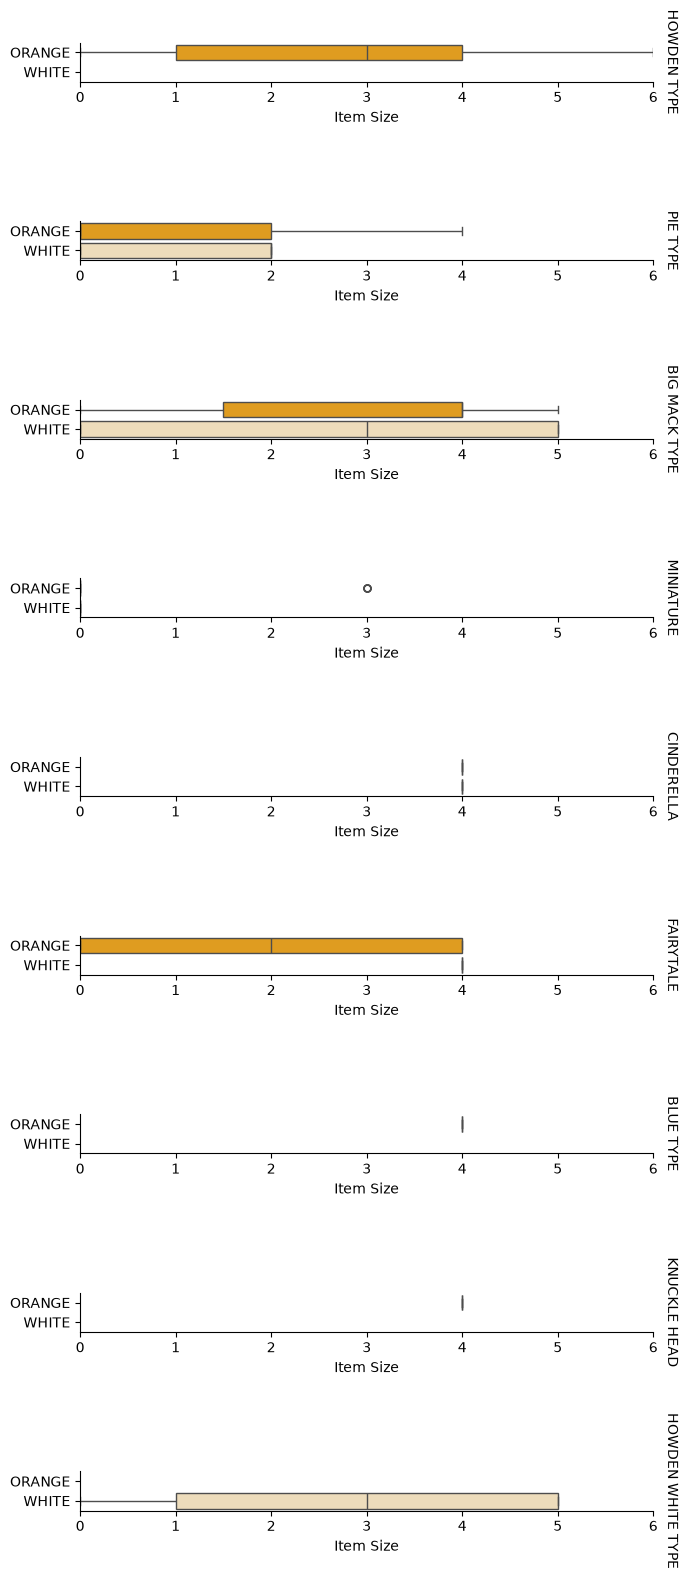

In [139]:
palette = {
'ORANGE': 'orange',
'WHITE': 'wheat',
}
pumpkins['Item Size'] = encoded_pumpkins['size__Item Size']

g = sns.catplot(
    data=pumpkins,
    x="Item Size", y="Color", row='Variety',
    kind="box", orient="h",
    sharex=False, margin_titles=True,
    height=1.8, aspect=4, palette=palette,
)
g.set(xlabel="Item Size", ylabel="").set(xlim=(0,6))
g.set_titles(row_template="{row_name}")

c:\Users\Adrian\Desktop\projects\ML-For-Beginners\.venv\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 66.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\Adrian\Desktop\projects\ML-For-Beginners\.venv\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 42.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


<Axes: xlabel='Color', ylabel='size__Item Size'>

c:\Users\Adrian\Desktop\projects\ML-For-Beginners\.venv\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 81.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\Adrian\Desktop\projects\ML-For-Beginners\.venv\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 53.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


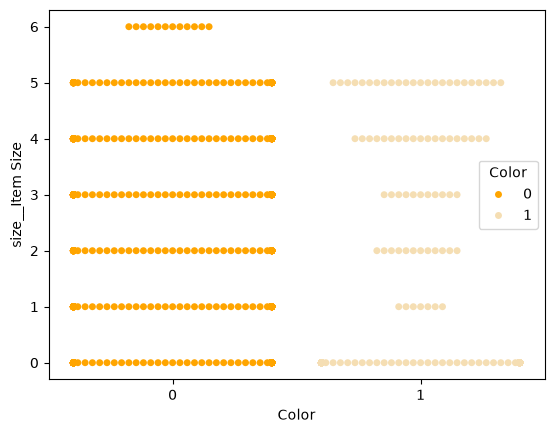

In [140]:
palette = {
0: 'orange',
1: 'wheat'
}
sns.swarmplot(x="Color", y="size__Item Size", data=encoded_pumpkins, hue='Color', palette=palette)

In [141]:
from sklearn.model_selection import train_test_split

X = encoded_pumpkins[encoded_pumpkins.columns.difference(['Color'])]
Y = encoded_pumpkins['Color']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

In [142]:
from sklearn.metrics import f1_score, classification_report 
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, Y_train)
predictions = model.predict(X_test)

print(classification_report(Y_test, predictions, target_names=le.classes_))
print('Predicted labels: ', predictions)
print('F1-score: ', f1_score(Y_test, predictions))

              precision    recall  f1-score   support

      ORANGE       0.91      0.94      0.92       187
       WHITE       0.64      0.54      0.58        39

    accuracy                           0.87       226
   macro avg       0.77      0.74      0.75       226
weighted avg       0.86      0.87      0.86       226

Predicted labels:  [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0 0 0 1
 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0
 1 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 1 0 0 1 0 0 0
 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0
 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1
 0 0 0 0]
F1-score:  0.5833333333333334


In [143]:
from sklearn.metrics import confusion_matrix
confusion_matrix(Y_test, predictions)

array([[175,  12],
       [ 18,  21]])

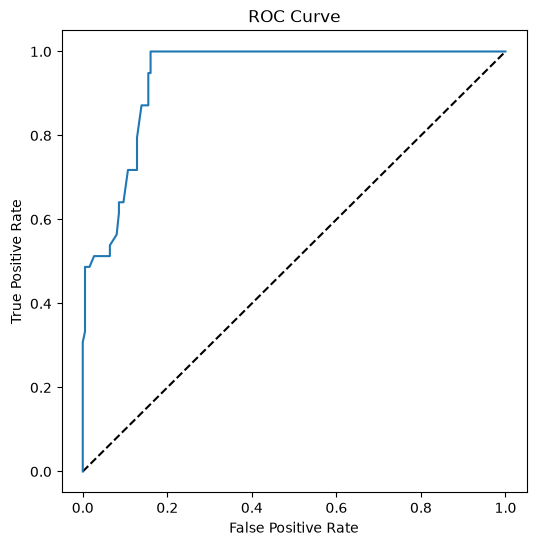

In [144]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

y_scores = model.predict_proba(X_test)
fpr, tpr, thresholds = roc_curve(Y_test, y_scores[:,1])

fig = plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], 'k--')
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

In [145]:
auc = roc_auc_score(Y_test,y_scores[:,1])
print(auc)

0.9404908816673523


- 1757 rows original; `dropna()` gives 0 for the whole dataset, because 9 columns were empty. I have removed those columns and left 1141 rows with target `Color`,
- 150 values in `Item Size` column were empty, I have filled them with `most_frequent` strategy,
- `STRIPED` (12 values) skipped, because it's too small to be useful,
- Model: accuracy: 0.87, AUC 0.94. `ORANGE` was predicted in 94% of cases, `WHITE` in 54%.
- Conclusion: AUC 0.94 with recall 0.54 for `WHITE` means that model distinguishes between `ORANGE` and `WHITE`. Accuracy is 0.87, because `WHITE` is only 19% of the dataset.